# Decision Model Evaluation Appendix — News Sentiment

Pre-computed evaluation for the Decision Models deep-dive session (Edition #1). Not run live — this produces the results table and figures used in the deck/doc.

**Use case:** financial news sentiment classification (positive / negative / neutral) — a direct stand-in for the kind of fast, calibrated, typed classification risk teams run at volume.

**Ground truth:** [Financial PhraseBank](https://huggingface.co/datasets/takala/financial_phrasebank) (Malo et al., 2014), `Sentences_AllAgree` subset — 2,264 analyst-labeled sentences from financial news, 100% annotator agreement.

**License note:** CC BY-NC-SA 3.0 — non-commercial research/education use (this session) is fine. The raw dataset is **not committed to this repo**; it's downloaded at runtime from Hugging Face.

**Angles evaluated:** accuracy/F1 vs. ground truth, calibration (Brier score), latency (p50/p95), and an illustrative cost-per-1k-decisions estimate.

**Compares:** the decision model (default: **Laya**, ModernBERT-421M, local, verified working on Apple Silicon via MPS) against a generic LLM prompted for JSON (default: Ollama/`qwen3.6`, local) — same pluggable-provider pattern as the live demo notebook.

**Why Laya, not Torchcast Decision:** Torchcast Decision 4B requires its CUDA-only serving stack for correct results (see the demo notebook's intro cell for the full explanation) — there's no legitimate way to self-host it on this machine. Laya is a standard ModernBERT encoder with documented MPS support, so it's the one actually live here.

## A note on what's real here

Every cell below runs for real against whatever providers are reachable. If Laya's server isn't up, that side falls back to a **clearly labeled SIMULATED** predictor so the pipeline still runs end to end for testing — but SIMULATED numbers are not a benchmark and must not be quoted in the deck or doc.

**Status: this notebook has been run live.** Both passes completed 100/100 with zero failures against a real local Laya server (English checkpoint, MPS) and a real local Ollama/`qwen3.6`. The `results` table and both figures below reflect actual measurements, not placeholders. One earlier run (interleaved calls, both checkpoints preloaded) hit intermittent `MPS OutOfMemoryError`s from running Laya and Ollama concurrently on this machine's unified memory — fixed by restarting Laya with a single checkpoint and switching to two sequential passes (see the "Run both systems" cells) instead of interleaving calls per sample.

## Setup

```bash
pip install datasets huggingface_hub pandas numpy scikit-learn matplotlib requests

# Decision model (see the live-demo notebook's Setup cell for details):
LAYA_DEVICE=mps LAYA_HOST=127.0.0.1 LAYA_PORT=8012 laya-serve

# LLM contrast:
ollama pull qwen3.6 && ollama serve
```

## Config

In [1]:
import json
import os
import random
import time

import numpy as np
import pandas as pd
import requests
from sklearn.metrics import accuracy_score, f1_score

# --- Decision model provider: "laya" (open-source, local, verified working) | "torchcast" (CUDA-only, NOT usable on Apple Silicon) | "jev" (TypeSafe API) ---
DECISION_PROVIDER = "laya"
LAYA_URL = "http://127.0.0.1:8012"
TORCHCAST_SERVER_URL = "http://127.0.0.1:8011"
JEV_MODEL = "jev-latest"

# --- LLM contrast provider: "ollama" (open-source, local) | "openai" | "claude" ---
LLM_PROVIDER = "ollama"
OLLAMA_URL = "http://localhost:11434"
OLLAMA_MODEL = "qwen3.6"
OPENAI_MODEL = "gpt-4o-mini"
CLAUDE_MODEL = "claude-sonnet-5"

# --- Eval run size ---
SAMPLE_SIZE = 100   # raise toward 2264 (the full AllAgree set) for a more rigorous, slower run
RANDOM_SEED = 7

LABELS = ["negative", "neutral", "positive"]  # fixed order used for probability vectors throughout

/Users/kfabo/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


In [2]:
LAYA_SIMULATED = True
if DECISION_PROVIDER == "laya":
    try:
        requests.get(f"{LAYA_URL}/health", timeout=2).raise_for_status()
        LAYA_SIMULATED = False
    except requests.RequestException:
        pass

TORCHCAST_SIMULATED = True
if DECISION_PROVIDER == "torchcast":
    try:
        requests.get(f"{TORCHCAST_SERVER_URL}/health", timeout=2).raise_for_status()
        TORCHCAST_SIMULATED = False
    except requests.RequestException:
        pass

OLLAMA_SIMULATED = True
if LLM_PROVIDER == "ollama":
    try:
        requests.get(f"{OLLAMA_URL}/api/version", timeout=2).raise_for_status()
        OLLAMA_SIMULATED = False
    except requests.RequestException:
        pass

_decision_simulated = (DECISION_PROVIDER == "laya" and LAYA_SIMULATED) or (DECISION_PROVIDER == "torchcast" and TORCHCAST_SIMULATED)
decision_tag = " [SIMULATED -- not a benchmark]" if _decision_simulated else " [LIVE]"
llm_tag = " [SIMULATED -- not a benchmark]" if LLM_PROVIDER == "ollama" and OLLAMA_SIMULATED else " [LIVE]"
print(f"Decision provider: {DECISION_PROVIDER}{decision_tag}")
print(f"LLM provider:       {LLM_PROVIDER}{llm_tag}")

Decision provider: laya [LIVE]
LLM provider:       ollama [LIVE]


## Ground truth data

Downloads the original Financial PhraseBank zip from the Hugging Face dataset repo (not the removed loading-script path) and parses `Sentences_AllAgree.txt` (`sentence@label`, Latin-1 encoded).

In [3]:
import zipfile
from huggingface_hub import hf_hub_download

zip_path = hf_hub_download(
    "takala/financial_phrasebank", "data/FinancialPhraseBank-v1.0.zip", repo_type="dataset"
)

with zipfile.ZipFile(zip_path) as zf:
    raw = zf.read("FinancialPhraseBank-v1.0/Sentences_AllAgree.txt").decode("latin-1")

all_examples = []
for line in raw.splitlines():
    line = line.strip()
    if not line:
        continue
    sentence, label = line.rsplit("@", 1)
    all_examples.append((sentence, label))

print(f"Loaded {len(all_examples)} labeled sentences (Sentences_AllAgree)")

random.seed(RANDOM_SEED)
sample = random.sample(all_examples, min(SAMPLE_SIZE, len(all_examples)))
print(f"Evaluating on {len(sample)} sampled sentences (seed={RANDOM_SEED})")

Loaded 2264 labeled sentences (Sentences_AllAgree)
Evaluating on 100 sampled sentences (seed=7)


## Decision model providers

In [4]:
SENTIMENT_QUESTIONS = {
    "sentiment": {
        "type": "choice",
        "instructions": "Classify the sentiment of this financial news sentence from the perspective of the company or asset it concerns.",
        "criteria": {
            "negative": "The sentence describes a negative development (losses, declines, downgrades, risk).",
            "neutral": "The sentence is factual/descriptive with no clear positive or negative framing.",
            "positive": "The sentence describes a positive development (growth, gains, upgrades, good news).",
        },
    }
}


def decide_laya(state: str, questions: dict) -> tuple[dict, float]:
    start = time.perf_counter()
    if LAYA_SIMULATED:
        time.sleep(random.uniform(0.03, 0.06))  # representative of laya's self-hosted 30-60ms range
        result = {"_simulated": True, "answers": {"sentiment": {"probabilities": _simulated_choice_probs(state)}}}
    else:
        response = requests.post(
            f"{LAYA_URL}/v1/systemone",
            json={"state": {"body": state}, "questions": questions},
            timeout=15,
        )
        response.raise_for_status()
        result = response.json()
    return result, time.perf_counter() - start


def decide_torchcast(state: str, questions: dict) -> tuple[dict, float]:
    """NOT usable on Apple Silicon -- see the demo notebook's intro cell."""
    start = time.perf_counter()
    if TORCHCAST_SIMULATED:
        time.sleep(random.uniform(0.07, 0.22))  # representative of the 70-500ms range
        result = {"_simulated": True, "sentiment": {"choice": _simulated_choice_probs(state)}}
    else:
        response = requests.post(
            f"{TORCHCAST_SERVER_URL}/v1/systemone",
            json={"state": state, "questions": questions},
            timeout=10,
        )
        response.raise_for_status()
        result = response.json()
    return result, time.perf_counter() - start


def decide_jev(state: str, questions: dict) -> tuple[dict, float]:
    """Not used by default -- drop-in path once Jev access is set up. Requires TYPESAFE_API_KEY."""
    api_key = os.environ.get("TYPESAFE_API_KEY")
    if not api_key:
        raise RuntimeError("Set TYPESAFE_API_KEY to use the Jev provider.")
    start = time.perf_counter()
    response = requests.post(
        "https://api.typesafe.ai/v1/systemone",
        headers={"Authorization": f"Bearer {api_key}"},
        json={"model": JEV_MODEL, "state": state, "questions": questions},
        timeout=10,
    )
    response.raise_for_status()
    return response.json(), time.perf_counter() - start


def decide(state: str, questions: dict) -> tuple[dict, float]:
    if DECISION_PROVIDER == "laya":
        return decide_laya(state, questions)
    if DECISION_PROVIDER == "torchcast":
        return decide_torchcast(state, questions)
    if DECISION_PROVIDER == "jev":
        return decide_jev(state, questions)
    raise ValueError(f"Unknown DECISION_PROVIDER: {DECISION_PROVIDER}")


def extract_choice_probs(result: dict, key: str) -> dict:
    """Returns {label: probability} for a 'choice' answer, regardless of provider response shape."""
    if DECISION_PROVIDER == "laya":
        return result["answers"][key]["probabilities"]
    if DECISION_PROVIDER in ("torchcast", "jev"):
        return result[key]["choice"]
    raise ValueError(DECISION_PROVIDER)


def _simulated_choice_probs(state: str) -> dict:
    """SIMULATED ONLY: a noisy, true-label-correlated distribution so the pipeline
    can be exercised end to end without a live server. Never a real prediction.
    """
    true_label = _state_to_true_label.get(state, "neutral")
    base = {lbl: 0.08 for lbl in LABELS}
    base[true_label] = 0.84
    noise = {lbl: random.uniform(-0.05, 0.05) for lbl in LABELS}
    probs = {lbl: max(0.01, base[lbl] + noise[lbl]) for lbl in LABELS}
    total = sum(probs.values())
    return {lbl: p / total for lbl, p in probs.items()}

## LLM contrast providers

In [5]:
def _sentiment_prompt(sentence: str) -> str:
    return (
        "Classify the sentiment of this financial news sentence as exactly one of "
        '"negative", "neutral", or "positive", from the perspective of the company or asset it concerns. '
        'Answer with ONLY a JSON object {"label": "negative"|"neutral"|"positive", "confidence": <0-1 float>}.\n\n'
        f"Sentence: {sentence}"
    )


def call_llm_ollama(prompt: str) -> tuple[dict, float]:
    start = time.perf_counter()
    if OLLAMA_SIMULATED:
        time.sleep(random.uniform(0.8, 2.2))
        result = {"_simulated": True, "label": "neutral", "confidence": 0.7}
    else:
        response = requests.post(
            f"{OLLAMA_URL}/api/generate",
            json={
                "model": OLLAMA_MODEL,
                "prompt": prompt,
                "format": "json",
                "stream": False,
                "think": False,  # qwen3.6 is a thinking model -- without this, JSON lands in "thinking", not "response"
            },
            timeout=60,
        )
        response.raise_for_status()
        result = json.loads(response.json()["response"])
    return result, time.perf_counter() - start


def call_llm_openai(prompt: str) -> tuple[dict, float]:
    """Not used by default -- drop-in path once an OPENAI_API_KEY is available."""
    from openai import OpenAI

    client = OpenAI()
    start = time.perf_counter()
    response = client.chat.completions.create(
        model=OPENAI_MODEL,
        messages=[{"role": "user", "content": prompt}],
        response_format={"type": "json_object"},
    )
    result = json.loads(response.choices[0].message.content)
    return result, time.perf_counter() - start


def call_llm_claude(prompt: str) -> tuple[dict, float]:
    """Not used by default -- drop-in path once an ANTHROPIC_API_KEY is available."""
    import anthropic

    client = anthropic.Anthropic()
    start = time.perf_counter()
    response = client.messages.create(
        model=CLAUDE_MODEL,
        max_tokens=128,
        messages=[{"role": "user", "content": prompt}],
    )
    result = json.loads(response.content[0].text)
    return result, time.perf_counter() - start


def call_llm_for_json(prompt: str) -> tuple[dict, float]:
    if LLM_PROVIDER == "ollama":
        return call_llm_ollama(prompt)
    if LLM_PROVIDER == "openai":
        return call_llm_openai(prompt)
    if LLM_PROVIDER == "claude":
        return call_llm_claude(prompt)
    raise ValueError(f"Unknown LLM_PROVIDER: {LLM_PROVIDER}")

## Run both systems over the sample

Two **sequential** passes, not interleaved per-sample: running Laya (MPS) and Ollama (also competing for this machine's unified memory) concurrently caused intermittent `MPS OutOfMemoryError`s under sustained load in an earlier run. Sequential passes avoid that cross-system resource contention entirely and are a cleaner benchmark design regardless -- nothing about measuring either system's own accuracy/latency requires the other to be mid-call at the same moment.

Each call is wrapped in try/except so one failure doesn't kill the run; failures are counted and excluded from metrics.

In [6]:
_state_to_true_label = {sentence: label for sentence, label in sample}  # used only by the SIMULATED path

decision_rows = []
decision_failures = 0

for i, (sentence, true_label) in enumerate(sample):
    try:
        result, elapsed = decide(sentence, SENTIMENT_QUESTIONS)
        choice = extract_choice_probs(result, "sentiment")
        probs = np.array([choice.get(lbl, 0.0) for lbl in LABELS])
        if probs.sum() == 0:
            raise ValueError(f"Empty choice distribution: {result}")
        probs = probs / probs.sum()
        pred_label = LABELS[int(np.argmax(probs))]
        decision_rows.append({"true": true_label, "pred": pred_label, "probs": probs, "latency": elapsed})
    except Exception as exc:
        decision_failures += 1
        print(f"[decision model] sample {i} failed: {exc}")

    if (i + 1) % 20 == 0:
        print(f"...decision model: {i + 1}/{len(sample)} done")

print(f"\nDecision model pass complete: {len(decision_rows)} ok, {decision_failures} failed")

...decision model: 20/100 done


...decision model: 40/100 done


...decision model: 60/100 done


...decision model: 80/100 done


...decision model: 100/100 done

Decision model pass complete: 100 ok, 0 failed


In [7]:
llm_rows = []
llm_failures = 0

for i, (sentence, true_label) in enumerate(sample):
    try:
        result, elapsed = call_llm_for_json(_sentiment_prompt(sentence))
        pred_label = result["label"].lower().strip()
        confidence = float(result.get("confidence", 1.0 / 3))
        # Approximate a per-class probability vector: mass on the predicted label,
        # remainder split evenly. This approximation itself illustrates a point from
        # the deep-dive: an LLM's self-reported confidence is not a true calibrated
        # per-class distribution the way a decision model's choice output is.
        other = (1 - confidence) / 2
        probs = np.array([confidence if lbl == pred_label else other for lbl in LABELS])
        llm_rows.append({"true": true_label, "pred": pred_label, "probs": probs, "latency": elapsed})
    except Exception as exc:
        llm_failures += 1
        print(f"[llm] sample {i} failed: {exc}")

    if (i + 1) % 20 == 0:
        print(f"...llm: {i + 1}/{len(sample)} done")

print(f"\nLLM pass complete: {len(llm_rows)} ok, {llm_failures} failed")

...llm: 20/100 done


...llm: 40/100 done


...llm: 60/100 done


...llm: 80/100 done


...llm: 100/100 done

LLM pass complete: 100 ok, 0 failed


## Metrics

In [8]:
# Illustrative pricing -- confirm against each provider's current pricing page before quoting externally.
PRICING = {
    "laya": {"input_per_1m": 0.0, "output_per_1m": 0.0, "note": "self-hosted (Apache-2.0), compute cost only"},
    "torchcast": {"input_per_1m": 0.0, "output_per_1m": 0.0, "note": "self-hosted, compute cost only (not usable on Apple Silicon)"},
    "jev": {"input_per_1m": 0.042, "output_per_1m": 0.0, "note": "TypeSafe pricing, Nov 2026: input-token-only billing"},
    "ollama": {"input_per_1m": 0.0, "output_per_1m": 0.0, "note": "self-hosted, compute cost only"},
    "openai": {"input_per_1m": 0.15, "output_per_1m": 0.60, "note": f"illustrative {OPENAI_MODEL} rate"},
    "claude": {"input_per_1m": 3.0, "output_per_1m": 15.0, "note": f"illustrative {CLAUDE_MODEL} rate"},
}


def estimate_tokens(text: str) -> float:
    return len(text.split()) * 1.3  # rough heuristic, not a real tokenizer


def brier_score(rows: list[dict]) -> float:
    scores = []
    for row in rows:
        one_hot = np.array([1.0 if lbl == row["true"] else 0.0 for lbl in LABELS])
        scores.append(np.sum((row["probs"] - one_hot) ** 2))
    return float(np.mean(scores))


def summarize(rows: list[dict], provider: str, output_tokens_est: float) -> dict:
    y_true = [r["true"] for r in rows]
    y_pred = [r["pred"] for r in rows]
    latencies = np.array([r["latency"] for r in rows]) * 1000  # ms
    avg_input_tokens = np.mean([estimate_tokens(s) for s, _ in sample])
    pricing = PRICING[provider]
    cost_per_1k = (
        avg_input_tokens * pricing["input_per_1m"] / 1000
        + output_tokens_est * pricing["output_per_1m"] / 1000
    ) * 1000  # per 1,000 decisions
    return {
        "provider": provider,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", labels=LABELS, zero_division=0),
        "brier_score": brier_score(rows),
        "latency_p50_ms": float(np.percentile(latencies, 50)),
        "latency_p95_ms": float(np.percentile(latencies, 95)),
        "est_cost_per_1k": cost_per_1k,
        "cost_note": pricing["note"],
    }


decision_summary = summarize(decision_rows, DECISION_PROVIDER, output_tokens_est=0)  # typed output, no generation
llm_summary = summarize(llm_rows, LLM_PROVIDER, output_tokens_est=15)  # short JSON completion

results = pd.DataFrame([decision_summary, llm_summary]).set_index("provider")
results

,accuracy,macro_f1,brier_score,latency_p50_ms,latency_p95_ms,est_cost_per_1k,cost_note
provider,,,,,,,
laya,0.92,0.911155,0.118036,42.732063,50.380912,0.0,"self-hosted (Apache-2.0), compute cost only"
ollama,0.85,0.863065,0.253279,1076.600751,1241.542615,0.0,"self-hosted, compute cost only"


## Figures

In [9]:
import matplotlib.pyplot as plt

# Dark theme matched to the deck (research-eng Marp theme).
SURFACE = "#1a1a19"
INK_PRIMARY = "#ffffff"
INK_SECONDARY = "#c3c2b7"
INK_MUTED = "#898781"
GRIDLINE = "#2c2c2a"
COLOR_DECISION = "#3987e5"  # categorical slot 1 (blue), dark-mode step
COLOR_LLM = "#d95926"       # categorical slot 6 (orange), dark-mode step -- validated: worst adjacent dE 26.8 (protan), 31.8 (normal)

plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "text.color": INK_PRIMARY,
    "axes.labelcolor": INK_SECONDARY,
    "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED,
    "axes.edgecolor": GRIDLINE,
    "grid.color": GRIDLINE,
    "font.family": "sans-serif",
})

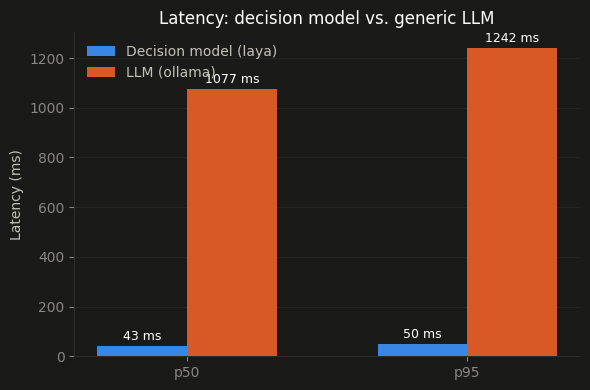

In [10]:
# Figure 1 -- latency comparison (p50 / p95)
fig, ax = plt.subplots(figsize=(6, 4))
metrics_x = ["p50", "p95"]
x = np.arange(len(metrics_x))
width = 0.32

decision_vals = [decision_summary["latency_p50_ms"], decision_summary["latency_p95_ms"]]
llm_vals = [llm_summary["latency_p50_ms"], llm_summary["latency_p95_ms"]]

bars_a = ax.bar(x - width / 2, decision_vals, width, label=f"Decision model ({DECISION_PROVIDER})", color=COLOR_DECISION)
bars_b = ax.bar(x + width / 2, llm_vals, width, label=f"LLM ({LLM_PROVIDER})", color=COLOR_LLM)

for bars in (bars_a, bars_b):
    for bar in bars:
        height = bar.get_height()
        ax.annotate(f"{height:.0f} ms", (bar.get_x() + bar.get_width() / 2, height),
                    textcoords="offset points", xytext=(0, 4), ha="center", color=INK_PRIMARY, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(metrics_x)
ax.set_ylabel("Latency (ms)")
ax.set_title("Latency: decision model vs. generic LLM", color=INK_PRIMARY, fontsize=12)
ax.grid(axis="y", linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, labelcolor=INK_SECONDARY)
fig.tight_layout()
fig.savefig("figures/latency_comparison.png", dpi=160)
plt.show()

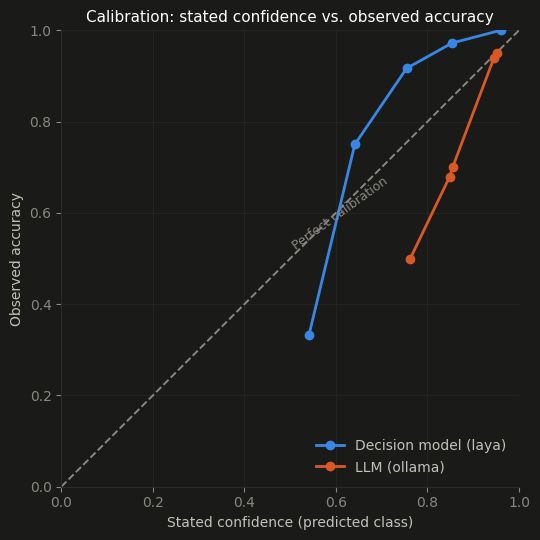

In [11]:
# Figure 2 -- calibration reliability diagram
def reliability_curve(rows: list[dict], n_buckets: int = 5):
    confidences = np.array([r["probs"][np.argmax(r["probs"])] for r in rows])
    correct = np.array([1.0 if r["pred"] == r["true"] else 0.0 for r in rows])
    edges = np.linspace(confidences.min() if len(confidences) else 0, 1.0, n_buckets + 1)
    xs, ys = [], []
    for lo, hi in zip(edges[:-1], edges[1:]):
        mask = (confidences >= lo) & (confidences <= hi)
        if mask.sum() == 0:
            continue
        xs.append(confidences[mask].mean())
        ys.append(correct[mask].mean())
    return xs, ys


fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.plot([0, 1], [0, 1], linestyle="--", linewidth=1.4, color=INK_MUTED)
ax.annotate("Perfect calibration", (0.5, 0.52), color=INK_MUTED, fontsize=9, rotation=36)

dx, dy = reliability_curve(decision_rows)
lx, ly = reliability_curve(llm_rows)
ax.plot(dx, dy, marker="o", linewidth=2, color=COLOR_DECISION, label=f"Decision model ({DECISION_PROVIDER})")
ax.plot(lx, ly, marker="o", linewidth=2, color=COLOR_LLM, label=f"LLM ({LLM_PROVIDER})")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xlabel("Stated confidence (predicted class)")
ax.set_ylabel("Observed accuracy")
ax.set_title("Calibration: stated confidence vs. observed accuracy", color=INK_PRIMARY, fontsize=11)
ax.grid(linewidth=0.6, alpha=0.6)
ax.set_axisbelow(True)
for spine in ["top", "right"]:
    ax.spines[spine].set_visible(False)
ax.legend(frameon=False, labelcolor=INK_SECONDARY, loc="lower right")
fig.tight_layout()
fig.savefig("figures/calibration_reliability.png", dpi=160)
plt.show()

## Takeaway for the deck/doc

Drop the `results` table and both PNGs from `figures/` into the written doc's Section 6 and a new deck appendix slide. Check: does the decision model sit closer to the diagonal in the reliability diagram? That's RLCD-style calibration training showing up empirically (Laya documents training with a Brier-score objective), not just asserted in Part 4 of the deck. Also check the latency gap now backed by a full distribution (p50/p95) across 100 real samples, not one anecdote from the live demo.